In [1]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.MNIST(root="~/.cache/", transform=transform, train=True, download=True)
test_data = datasets.MNIST(root="~/.cache/", transform=transform, train=False)
print(train_data[0][0].shape)

torch.Size([1, 28, 28])


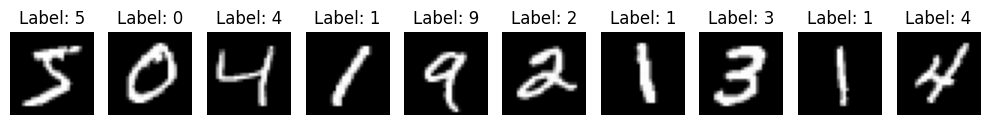

In [2]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from quantizer import VectorQuantizer


class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),   # (28x28) → (14x14)
            nn.ReLU(),
            nn.Conv2d(16, 64, kernel_size=4, stride=2, padding=1),  # (14x14) → (7x7)
            nn.ReLU(),
            nn.Conv2d(64, 16, kernel_size=4, stride=2, padding=1),  # (7x7) → (3x3)
        )

    def forward(self, x):
        return self.encoder(x)  # (B, 16, 3, 3)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(16, 64, kernel_size=4, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 16, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid() # 输出范围控制在 [0,1]，适合图像重建
        )

    def forward(self, x):
        return self.decoder(x)  # (B, 1, 28, 28)


class VQVAE(nn.Module):
    def __init__(self, n_e, e_dim, norm_weight=True, beta=1.):
        super().__init__()
        self.encoder = Encoder()
        self.quantizer = VectorQuantizer(n_e, e_dim, norm_weight, beta)
        self.decoder = Decoder()

    def forward(self, x: torch.Tensor):
        # (B, C, H, W)
        z = self.encoder(x)
        z_q, indices, q_loss, codebook_usage = self.quantizer(z)
        x_q = self.decoder(z_q)

        return x_q, indices, q_loss, codebook_usage
    
    def encode(self, x: torch.Tensor):
        # (B, C, H, W)
        z = self.encoder(x)
        z_q, *_ = self.quantizer(z)
        return z_q
    
    def decode(self, z_q: torch.Tensor):
        # (B, C, H, W)
        x_q = self.decoder(z_q)
        return x_q

In [4]:
vqvae = VQVAE(n_e=128, e_dim=9)

x: torch.Tensor = train_data[0][0]
x = x.unsqueeze(0)  # 添加batch维度

x_q, indices, vq_loss, codebook_usage = vqvae(x) 
print(x_q.shape)
print(indices.shape) # use 16 tokens to encode one image
print(codebook_usage.shape)

z_q = vqvae.encode(x)
print(z_q.shape)



torch.Size([1, 1, 28, 28])
torch.Size([1, 16])
torch.Size([128])
torch.Size([1, 16, 3, 3])


In [5]:
vqvae = VQVAE(n_e=128, e_dim=9)

dataloader = torch.utils.data.DataLoader(train_data, batch_size=512, shuffle=True, num_workers=4)
optimizer = torch.optim.Adam(vqvae.parameters(), lr=1e-3)
epochs = 30

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


vqvae.to(device).train()
for epoch in range(epochs):
    for img, _ in dataloader:
        img = img.to(device)

        x_q, _, q_loss, _ = vqvae(img)
        loss = F.mse_loss(x_q, img) + q_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")



Epoch 1/30, Loss: 0.0757
Epoch 5/30, Loss: 0.0361
Epoch 10/30, Loss: 0.0322
Epoch 15/30, Loss: 0.0277
Epoch 20/30, Loss: 0.0252
Epoch 25/30, Loss: 0.0225
Epoch 30/30, Loss: 0.0224


[[ 89  90 109  70 100  76 110  14 112  53  28 100 112  19  96  33]
 [ 13  57  86  98  30  76 118  69  84  38 100 100  19 119  20  91]
 [ 63  15  27  25  30  73 110  47 106  38 108 100  56 101  65   1]
 [ 63  11  30  67 111   3 123  18  58  90  15  41  77 103  43   2]
 [ 63  48   7  23 118  86 123  35 126  58   9  18  22  14 102   1]
 [ 63  15  27  62 115  76 110  47 100  44 108 100  80 113  99   1]
 [ 37 100  14 107 127  51  65  83  43  96  73 117  68 104  76  33]
 [ 63  26  87  70 114 108  37   1 105  80   4 117  22  62 102  17]
 [ 63  11  31  50  67  14 115  56  53 115   3  18  50   0  43   2]
 [ 63  20 109  38 121 127  37  82  34  32 109 108  66  28  80  33]]


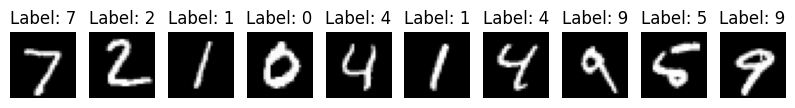

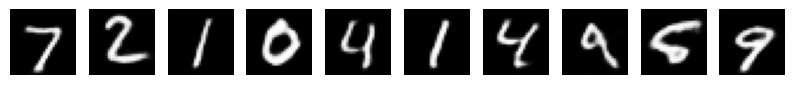

In [6]:
# 遍历前10张图片
x = torch.vstack([test_data[i][0] for i in range(10)]).unsqueeze(1).to(device)
x_q, ids, vq_loss, _ = vqvae(x)
x_q = x_q.cpu().detach()
x_p = vqvae.decode(vqvae.encode(x)).cpu().detach()

print(ids.cpu().numpy())

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = test_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = x_p[i], test_data[i][1]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.axis('off')  # 关闭坐标轴

3.2407122e-05


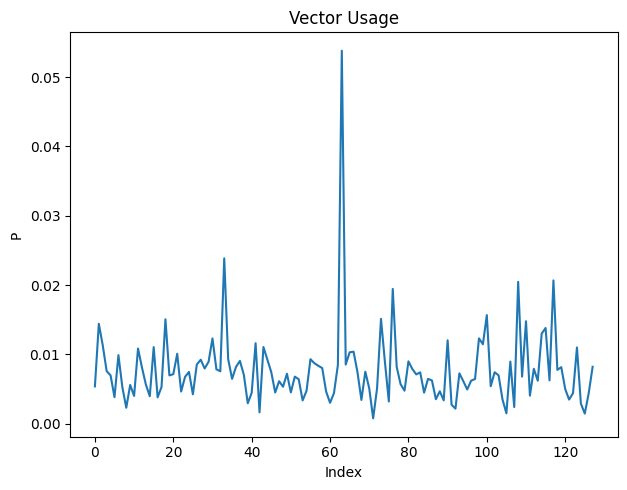

In [7]:
test_loader = torch.utils.data.DataLoader(test_data, batch_size=512, shuffle=False, num_workers=4)

vqvae.eval()
usage = 0
for img, _ in test_loader:
    img = img.to(device)

    _, _, _, u = vqvae(img)
    usage += u.cpu().numpy() * len(img)

usage /= len(test_data)

print(usage.var())
plt.figure(figsize=(12, 5))

# 折线图
plt.subplot(1, 2, 1)
plt.plot(usage)
plt.title('Vector Usage')
plt.xlabel('Index')
plt.ylabel('P')


plt.tight_layout()
plt.show()